# 04 · Exercise 3: what do image and RNAseq embeddings add?

The question is **what the embeddings add to a strong clinical model**, not whether they predict the
target on their own. So we keep the Exercise 1 forecast and learn a **correction** from the embeddings:

`prediction = Exercise 1 forecast + correction(embedding)`

The correction is a ridge regression fitted on the out-of-fold errors of Exercise 1, on the same folds.
We answer, following the brief's guidelines:
1. Who has embeddings, and how do they differ from the cohort?
2. Do technical variables (device, batch) confound the embeddings?
3. What do the image embeddings encode?
4. Do embeddings improve on Exercise 1 for the same patients? (3a images, 3b images + RNAseq)
5. How does the benefit grow with the number of training patients?
6. For which patients do images help?
7. Does RNAseq help identify super-responders?

In [1]:
TEAM_NAME = "IHS4casters"

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

DATA, WORK, SUB = Path("public"), Path("work"), Path("submissions")
END = pd.Timestamp("2025-12-31")
SPLITS = ["train", "test_1", "test_2"]
SEED = 42
ALPHAS = np.logspace(-1, 5, 25)
FLOOR = 0.25            # an additive correction must not push a forecast below a plausible minimum (train min ≈ 0.27)
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "figure.dpi": 110})
pd.set_option("display.width", 200)

def letters(axes):
    for a, l in zip(np.ravel(axes), "ABCDEF"):
        a.text(-0.02, 1.03, l, transform=a.transAxes, fontweight="bold", fontsize=14, ha="right", va="bottom")

FLARE_FACTOR = json.load(open(WORK / "ex1_config.json"))["type_factor"]["flare_reactive"]
F = {s: pd.read_parquet(WORK / f"features_{s}.parquet") for s in SPLITS}
oof1 = pd.read_parquet(WORK / "oof_ex1.parquet")
pred1 = pd.read_parquet(WORK / "pred_ex1.parquet").pred
sr = pd.read_parquet(WORK / "sr_labels_train.parquet").sr
sr_before = pd.read_parquet(WORK / "oof_ex2.parquet").sr_prob_before

def load_emb(split):
    v = pd.read_csv(DATA / split / "visits.csv", usecols=["visit_id", "visit_type", "ihs4_score"])
    im = (pd.read_csv(DATA / split / "images_metadata.csv", parse_dates=["capture_date"])
          .merge(pd.read_csv(DATA / split / "images_embeddings.csv"), on="image_id").merge(v, on="visit_id", how="left"))
    im["days_ago"] = (END - im.capture_date).dt.days
    im["scored"] = im.ihs4_score.notna().astype(int)
    rn = (pd.read_csv(DATA / split / "rnaseq_metadata.csv", parse_dates=["collection_date"])
          .merge(pd.read_csv(DATA / split / "rnaseq_embeddings.csv"), on="rnaseq_sample_id"))
    return im.set_index("patient_id"), rn.set_index("patient_id")

IM, RN = {}, {}
for s in SPLITS:
    IM[s], RN[s] = load_emb(s)
IMG_COLS = [c for c in IM["train"] if c.startswith("image_dim")]
RNA_COLS = [c for c in RN["train"] if c.startswith("rnaseq_dim")]

/tmp/ipykernel_36113/630465207.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  im["days_ago"] = (END - im.capture_date).dt.days
/tmp/ipykernel_36113/630465207.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  im["scored"] = im.ihs4_score.notna().astype(int)
/tmp/ipykernel_36113/630465207.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-f

## 1. Who has embeddings, and how do they differ from the cohort?

Every claim about the embeddings applies only to these patients, so we first describe them against the
whole train cohort, including how well Exercise 1 already does for them.

In [2]:
tr = F["train"].assign(y=oof1.y, err=(oof1.pred_orig - oof1.y).abs())
def describe(f):
    return pd.Series({"patients": len(f), "mean target": f.y.mean(), "on biologic": f.on_bio.mean(),
                      "median days on biologic (if on)": f.days_on_bio.median(), "IHS4 scores in last year": f.n_scored_365d.mean(),
                      "Exercise 1 MAE": f.err.mean()})
coverage = pd.DataFrame({s: {"with image": len(IM[s]), "with RNAseq": len(RN[s]), "with both": len(IM[s].index.intersection(RN[s].index))} for s in SPLITS})
print(coverage, "\n")
print(f"image visits that were scored: {IM['train'].scored.mean():.0%} | RNAseq taken on the current biologic start date: "
      f"{(RN['train'].collection_date == END - pd.to_timedelta(F['train'].loc[RN['train'].index, 'days_on_bio'], unit='D')).mean():.0%}")
pd.DataFrame({"all train": describe(tr), "with image": describe(tr.loc[IM["train"].index]),
              "with image + RNAseq": describe(tr.loc[RN["train"].index])}).round(2)

             train  test_1  test_2
with image    2800     600     600
with RNAseq    600     200     200
with both      600     200     200 

image visits that were scored: 66% | RNAseq taken on the current biologic start date: 100%


,all train,with image,with image + RNAseq
patients,21000.00,2800.00,600.00
mean target,8.32,9.12,8.72
on biologic,0.41,0.70,1.00
median days on biologic (if on),867.00,561.00,97.50
IHS4 scores in last year,3.84,6.25,6.47
Exercise 1 MAE,1.43,1.48,2.07


**Results.**

* Image patients are more severe (target 9.1 vs 8.3), mostly on a biologic (70 %), more often scored, and
  started their biologic more recently.
* A third of their photos come from flare visits nobody scored.
* RNAseq patients are all on a biologic and were all sampled on the day it started. Most started very
  recently (median 98 days), so their records show almost no response yet.
* **Exercise 1 is weakest exactly there** (MAE 2.07 vs 1.43 overall).

## 2. Do technical variables (device, batch) confound the embeddings?

Following the brief, before claiming any embedding effect we test whether `device_id` (images) or
`batch_id` (RNAseq) predicts the target or the Exercise 1 error on its own, and whether it tracks the
collection date (Kruskal–Wallis p-values). We also check whether the technical label can be **read from
the embedding**, before and after removing each device's or batch's average embedding ("centering").

In [3]:
res1 = oof1.y - oof1.pred_orig

def kw(values, groups):
    d = pd.DataFrame({"v": values, "g": groups}).dropna()
    return kruskal(*[x.v.values for _, x in d.groupby("g")]).pvalue

conf = pd.DataFrame({
    "device_id (images)": {"target": kw(oof1.y.loc[IM["train"].index].values, IM["train"].device_id.values),
                           "Exercise 1 error": kw(res1.loc[IM["train"].index].values, IM["train"].device_id.values),
                           "collection date": kw(IM["train"].capture_date.map(pd.Timestamp.toordinal).values, IM["train"].device_id.values)},
    "batch_id (RNAseq)": {"target": kw(oof1.y.loc[RN["train"].index].values, RN["train"].batch_id.values),
                          "Exercise 1 error": kw(res1.loc[RN["train"].index].values, RN["train"].batch_id.values),
                          "collection date": kw(RN["train"].collection_date.map(pd.Timestamp.toordinal).values, RN["train"].batch_id.values)},
}).T

def embed(dct, cols, group, center, k):
    """Standardise, optionally center per device/batch, then PCA. Fitted on all splits pooled (no target used)."""
    X = pd.concat([d[cols + [group]].assign(split=s) for s, d in dct.items()])
    E = X[cols].values.astype(float); E = (E - E.mean(0)) / E.std(0)
    if center:
        E = E - pd.DataFrame(E).groupby(X[group].values).transform("mean").values
    Z = PCA(k, random_state=SEED).fit_transform(E)
    return pd.DataFrame(Z, index=X.index, columns=[f"pc{i}" for i in range(k)]).assign(split=X.split.values)

def part(Z, split, ids):
    return Z[Z.split == split].drop(columns="split").loc[ids]

read = {}
for name, dct, cols, grp, k in [("device from image", IM, IMG_COLS, "device_id", 16), ("batch from RNAseq", RN, RNA_COLS, "batch_id", 8)]:
    lab = dct["train"][grp].values
    for center in [False, True]:
        Zt = part(embed(dct, cols, grp, center, k), "train", dct["train"].index).values
        acc = (cross_val_predict(LogisticRegression(max_iter=3000), Zt, lab, cv=5) == lab).mean()
        read[(name, "centered" if center else "raw")] = acc
    read[(name, "chance")] = pd.Series(lab).value_counts(normalize=True).max()
print(pd.Series(read).unstack().round(3), "\n")
conf.map(lambda p: f"{p:.2g}")

/tmp/ipykernel_36113/4137078897.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X = pd.concat([d[cols + [group]].assign(split=s) for s, d in dct.items()])
/tmp/ipykernel_36113/4137078897.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X = pd.concat([d[cols + [group]].assign(split=s) for s, d in dct.items()])
/tmp/ipykernel_36113/4137078897.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns

                   centered  chance    raw
batch from RNAseq     0.333   0.343  0.543
device from image     0.114   0.154  0.481 



/tmp/ipykernel_36113/4137078897.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X = pd.concat([d[cols + [group]].assign(split=s) for s, d in dct.items()])
/tmp/ipykernel_36113/4137078897.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X = pd.concat([d[cols + [group]].assign(split=s) for s, d in dct.items()])
/tmp/ipykernel_36113/4137078897.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns

,target,Exercise 1 error,collection date
device_id (images),0.72,0.45,1.3e-61
batch_id (RNAseq),0.63,0.67,6.8e-27


**Results.**

* `device_id` and `batch_id` are strongly tied to collection date (p = 10⁻⁶¹ and 10⁻²⁷). Because RNAseq is
  taken at biologic start, batch is also tied to time on treatment.
* **Neither predicts the target (p = 0.72, 0.63) nor the Exercise 1 error (p = 0.45, 0.67)**: on their own,
  they carry no outcome information.
* The embeddings do encode them (device readable 48 % vs 15 % chance; batch 54 % vs 34 %), and centering
  removes that.
* We therefore keep both versions in section 4 to check that centering does not change the conclusions.

## 3. What do the image embeddings encode?

Each image comes from a flare visit. We measure, with 5-fold ridge regression on the 16 image components,
how much of three things the image explains (R²): the IHS4 of **its own visit** (scored visits only),
the 6-month **target**, and the **Exercise 1 error**, i.e. what the clinical model misses.

In [4]:
def r2_cv(Z, t):
    p = cross_val_predict(RidgeCV(alphas=ALPHAS), Z, t, cv=5)
    return 1 - ((t - p) ** 2).sum() / ((t - t.mean()) ** 2).sum()

ZI = embed(IM, IMG_COLS, "device_id", False, 16)
ZR = embed(RN, RNA_COLS, "batch_id", False, 8)
zi_tr, im_tr = part(ZI, "train", IM["train"].index), IM["train"]
s = im_tr.scored.values == 1
pd.Series({"IHS4 of the image's own visit": r2_cv(zi_tr.values[s], im_tr.ihs4_score.values[s]),
           "6-month target": r2_cv(zi_tr.values, oof1.y.loc[im_tr.index].values),
           "Exercise 1 error": r2_cv(zi_tr.values, res1.loc[im_tr.index].values)}, name="R² from image").round(3).to_frame()

/tmp/ipykernel_36113/4137078897.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X = pd.concat([d[cols + [group]].assign(split=s) for s, d in dct.items()])
/tmp/ipykernel_36113/4137078897.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X = pd.concat([d[cols + [group]].assign(split=s) for s, d in dct.items()])
/tmp/ipykernel_36113/4137078897.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns

,R² from image
IHS4 of the image's own visit,0.548
6-month target,0.392
Exercise 1 error,-0.006


**Results.**

* The image explains **55 % of the variance of its own visit's IHS4** and 39 % of the 6-month target.
* It explains **none of the Exercise 1 error** (R² ≈ 0). On average, what the photo shows is already in the
  records.
* We therefore expect images to help only where records are thin, such as unscored flares, recent
  starters and short histories.

## 4. Do embeddings improve on Exercise 1 for the same patients?

**The image correction** has two steps:
1. A ridge model reads the IHS4 of the flare visit from the photo (`g`), trained on scored image visits.
   It works even when nobody scored that visit.
2. A ridge model predicts the Exercise 1 error from: the gap between the photo's level and the forecast
   (`g / flare factor − forecast`), that gap × photo recency and × "visit unscored", and the image
   components faded by photo age.

**The RNAseq correction** adds the 8 RNAseq components to the same model. Following the brief, 3b is
trained only on the 600 train patients that have both embeddings. On those 600 we compare three models:
Exercise 1, images, and images + RNAseq. Gains get paired bootstrap 95 % intervals. Each model is also
applied to the thinned (pseudo‑test_2) Exercise 1 forecasts.

In [5]:
def design(z, m, g_hat, base):
    rec, uns = np.exp(-m.days_ago.values / 365), 1 - m.scored.values
    d = g_hat / FLARE_FACTOR - base
    X = pd.DataFrame({"gap": d, "gap_x_recency": d * rec, "gap_x_unscored": d * uns, "gap_x_both": d * rec * uns,
                      "recency": rec, "unscored": uns}, index=m.index)
    return X.join(z.mul(rec, axis=0).add_suffix("_x_recency"))

def fit_g(z, m):
    s = m.scored.values == 1
    return RidgeCV(alphas=ALPHAS).fit(z.values[s], m.ihs4_score.values[s])

def correction(z_tr, m_tr, base_tr, r_tr, z_ap, m_ap, base_ap, rna_tr=None, rna_ap=None):
    """Fit on training patients, return the predicted Exercise 1 error for the apply set."""
    g_tr = np.zeros(len(m_tr))                       # out-of-fold g for training rows
    for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(z_tr, m_tr.scored):
        g_tr[b] = fit_g(z_tr.iloc[a], m_tr.iloc[a]).predict(z_tr.iloc[b].values)
    g_ap = fit_g(z_tr, m_tr).predict(z_ap.values)
    X_tr, X_ap = design(z_tr, m_tr, g_tr, base_tr), design(z_ap, m_ap, g_ap, base_ap)
    if rna_tr is not None:
        X_tr, X_ap = X_tr.join(rna_tr.add_prefix("rna_")), X_ap.join(rna_ap.add_prefix("rna_"))
    mu, sd = X_tr.mean(), X_tr.std().replace(0, 1)
    model = RidgeCV(alphas=ALPHAS).fit(((X_tr - mu) / sd).values, r_tr)
    return model.predict(((X_ap - mu) / sd).values)

def cv_correct(ids, use_rna, train_mask=None, ZI_=ZI, ZR_=ZR):
    """Out-of-fold corrected forecasts (original and thinned base) for the patients in ids."""
    fo, y_, bo, bs = oof1.fold.loc[ids].values, oof1.y.loc[ids].values, oof1.pred_orig.loc[ids].values, oof1.pred_sim.loc[ids].values
    z, m = part(ZI_, "train", ids), IM["train"].loc[ids]
    rz = part(ZR_, "train", ids) if use_rna else None
    po, ps = np.zeros(len(ids)), np.zeros(len(ids))
    for k in range(5):
        a = (fo != k) & (train_mask if train_mask is not None else True); b = fo == k
        args = (z.iloc[a], m.iloc[a], bo[a], y_[a] - bo[a])
        extra = (rz.iloc[a], rz.iloc[b]) if use_rna else (None, None)
        po[b] = bo[b] + correction(*args, z.iloc[b], m.iloc[b], bo[b], *extra)
        ps[b] = bs[b] + correction(*args, z.iloc[b], m.iloc[b], bs[b], *extra)
    return np.maximum(po, FLOOR), np.maximum(ps, FLOOR)

def paired(new, old, y_, w=None, n=2000):
    """Mean change in absolute error (new − old) with a paired bootstrap 95% interval."""
    r = np.random.default_rng(SEED); d = np.abs(new - y_) - np.abs(old - y_); w = np.ones(len(d)) if w is None else w
    i = r.integers(0, len(d), (n, len(d)))
    lo, hi = np.percentile((d[i] * w[i]).sum(1) / w[i].sum(1), [2.5, 97.5])
    return f"{np.average(d, weights=w):+.3f} ({lo:+.3f} to {hi:+.3f})"

ids_im, ids_b = IM["train"].index, RN["train"].index
po3a, ps3a = cv_correct(ids_im, False)
po_img600, ps_img600 = cv_correct(ids_b, False)
po3b, ps3b = cv_correct(ids_b, True)
po3a_c, ps3a_c = cv_correct(ids_im, False, ZI_=embed(IM, IMG_COLS, "device_id", True, 16))
po3b_c, ps3b_c = cv_correct(ids_b, True, ZR_=embed(RN, RNA_COLS, "batch_id", True, 8))

table = []
for grp, ids, name, ntr, po, ps in [
        ("2,800 image patients", ids_im, "Exercise 1", "21,000", oof1.pred_orig.loc[ids_im].values, oof1.pred_sim.loc[ids_im].values),
        ("2,800 image patients", ids_im, "+ images (3a)", "2,800", po3a, ps3a),
        ("2,800 image patients", ids_im, "+ images, device-centered", "2,800", po3a_c, ps3a_c),
        ("600 image + RNAseq patients", ids_b, "Exercise 1", "21,000", oof1.pred_orig.loc[ids_b].values, oof1.pred_sim.loc[ids_b].values),
        ("600 image + RNAseq patients", ids_b, "+ images", "600", po_img600, ps_img600),
        ("600 image + RNAseq patients", ids_b, "+ images + RNAseq (3b)", "600", po3b, ps3b),
        ("600 image + RNAseq patients", ids_b, "+ images + RNAseq, batch-centered", "600", po3b_c, ps3b_c)]:
    y_, w = oof1.y.loc[ids].values, oof1.w_test2.loc[ids].values
    bo, bs = oof1.pred_orig.loc[ids].values, oof1.pred_sim.loc[ids].values
    table.append({"patients": grp, "model": name, "trained on": ntr, "MAE test_1 proxy": round(np.abs(po - y_).mean(), 3),
                  "MAE pseudo-test_2": round(np.average(np.abs(ps - y_), weights=w), 3),
                  "Δ vs Ex1, test_1 proxy (95% CI)": "" if name == "Exercise 1" else paired(po, bo, y_),
                  "Δ vs Ex1, pseudo-test_2 (95% CI)": "" if name == "Exercise 1" else paired(ps, bs, y_, w)})
pd.DataFrame(table).set_index(["patients", "model"])

/tmp/ipykernel_36113/4137078897.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X = pd.concat([d[cols + [group]].assign(split=s) for s, d in dct.items()])
/tmp/ipykernel_36113/4137078897.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X = pd.concat([d[cols + [group]].assign(split=s) for s, d in dct.items()])
/tmp/ipykernel_36113/4137078897.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns

trained on  MAE test_1 proxy  MAE pseudo-test_2 Δ vs Ex1, test_1 proxy (95% CI) Δ vs Ex1, pseudo-test_2 (95% CI)
patients                    model                                                                                                                                             
2,800 image patients        Exercise 1                            21,000             1.482              1.671                                                                 
                            + images (3a)                          2,800             1.487              1.642       +0.005 (-0.009 to +0.019)        -0.028 (-0.049 to -0.008)
                            + images, device-centered              2,800             1.485              1.645       +0.003 (-0.010 to +0.016)        -0.025 (-0.045 to -0.006)
600 image + RNAseq patients Exercise 1                            21,000             2.072              2.279                                                                 
                            + images                                 600             1.909              2.022       -0.163 (-0.257 to -0.075)        -0.257 (-0.398 to -0.122)
                            + images + RNAseq (3b)                   600             1.711              1.663       -0.360 (-0.479 to -0.243)        -0.616 (-0.823 to -0.430)
                            + images + RNAseq, batch-centered        600             1.726              1.678       -0.346 (-0.462 to -0.228)        -0.601 (-0.802 to -0.420)

**Results.**

* **3a, images on the 2,800 image patients:** no gain on train-like data (+0.005, CI −0.009 to +0.019),
  and a small, real gain under sparse documentation (−0.028, CI −0.049 to −0.008).
* **3b, on the 600 patients with both embeddings:**
  * Exercise 1 has MAE 2.07.
  * Images bring it to 1.91 (−0.16). These patients are recent starters, the subgroup where images help
    (section 6).
  * **Images + RNAseq bring it to 1.71 (−0.36, CI −0.48 to −0.24)**, and to 1.66 on the pseudo‑test_2
    (−0.62).
* **RNAseq roughly doubles the image gain**, using the same 600 training patients.
* Centering per device or batch changes nothing meaningful, so technical variation is not what the
  corrections learn.

## 5–6. How does the benefit grow with training size, and for which patients do images help?

**Volume (A, B).** We refit each correction on random subsets of the training folds and measure the
gain over Exercise 1 on the held-out folds (3 repeats). **Subgroups (C).** The image gain (3a) inside
groups the brief suggests: short histories, recent biologic starters, low-documentation practitioners
and super-responders, plus unscored image visits.

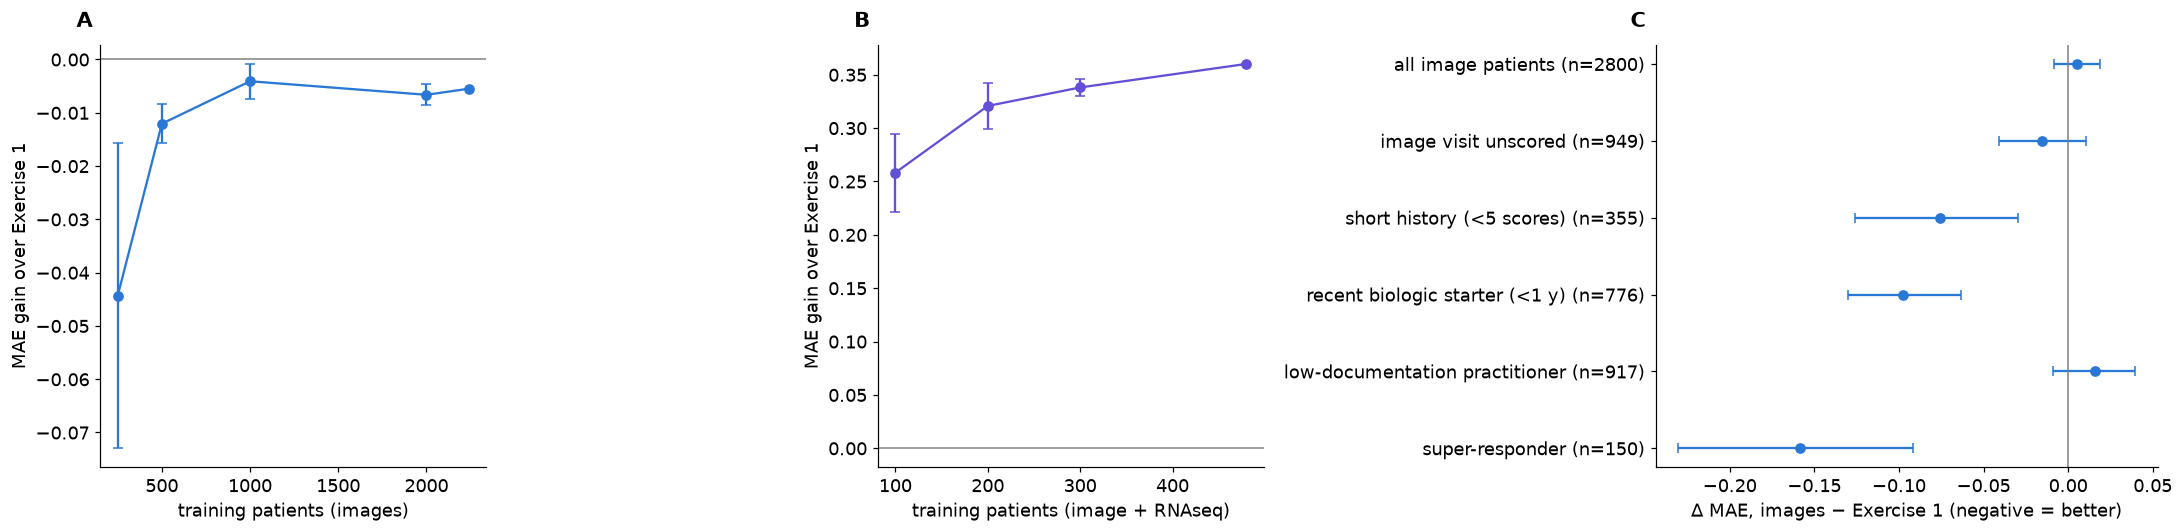

,n,Δ MAE,lo,hi
group,,,,
all image patients,2800,0.005,-0.009,0.019
image visit unscored,949,-0.016,-0.041,0.010
short history (<5 scores),355,-0.076,-0.126,-0.029
recent biologic starter (<1 y),776,-0.098,-0.130,-0.063
low-documentation practitioner,917,0.016,-0.009,0.039
super-responder,150,-0.158,-0.230,-0.092


In [6]:
rng = np.random.default_rng(SEED)
def gain(ids, po):
    y_ = oof1.y.loc[ids].values
    return np.abs(oof1.pred_orig.loc[ids].values - y_).mean() - np.abs(po - y_).mean()

curve_img = {n: [gain(ids_im, cv_correct(ids_im, False, rng.random(len(ids_im)) < n / (0.8 * len(ids_im)))[0]) for _ in range(3)]
             for n in [250, 500, 1000, 2000, 2240]}
curve_rna = {n: [gain(ids_b, cv_correct(ids_b, True, rng.random(len(ids_b)) < n / (0.8 * len(ids_b)))[0]) for _ in range(3)]
             for n in [100, 200, 300, 480]}

f_im = F["train"].loc[ids_im]
y_im, b_im = oof1.y.loc[ids_im].values, oof1.pred_orig.loc[ids_im].values
groups = {"all image patients": np.ones(len(ids_im), bool),
          "image visit unscored": IM["train"].loc[ids_im].scored.values == 0,
          "short history (<5 scores)": f_im.n_scored.values < 5,
          "recent biologic starter (<1 y)": (f_im.on_bio.values == 1) & (f_im.days_on_bio.values < 365),
          "low-documentation practitioner": f_im.pr_score_rate.values <= F["train"].pr_score_rate.quantile(1 / 3),
          "super-responder": sr.reindex(ids_im).fillna(0).values == 1}
sub_rows = []
for gname, msk in groups.items():
    d = np.abs(po3a - y_im)[msk] - np.abs(b_im - y_im)[msk]
    i = np.random.default_rng(SEED).integers(0, len(d), (2000, len(d)))
    lo, hi = np.percentile(d[i].mean(1), [2.5, 97.5])
    sub_rows.append({"group": gname, "n": int(msk.sum()), "Δ MAE": d.mean(), "lo": lo, "hi": hi})
subg = pd.DataFrame(sub_rows).set_index("group")

fig, ax = plt.subplots(1, 3, figsize=(20, 5), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for a, curve, c, lab_ in [(ax[0], curve_img, PAL[0], "training patients (images)"), (ax[1], curve_rna, PAL[5], "training patients (image + RNAseq)")]:
    xs = list(curve); m_ = [np.mean(curve[n]) for n in xs]; sd = [np.std(curve[n]) for n in xs]
    a.errorbar(xs, m_, yerr=sd, marker="o", color=c, capsize=3); a.axhline(0, color="grey", lw=1)
    a.set_xlabel(lab_); a.set_ylabel("MAE gain over Exercise 1")
sg = subg.iloc[::-1]
ax[2].errorbar(sg["Δ MAE"], range(len(sg)), xerr=[sg["Δ MAE"] - sg.lo, sg.hi - sg["Δ MAE"]], fmt="o", color=PAL[0], capsize=3)
ax[2].set_yticks(range(len(sg)), [f"{g} (n={n})" for g, n in zip(sg.index, sg.n)]); ax[2].axvline(0, color="grey", lw=1)
ax[2].set_xlabel("Δ MAE, images − Exercise 1 (negative = better)")
letters(ax); plt.tight_layout(); plt.show()
subg.round(3)

**Results.**

* **A.** With few training patients the image correction slightly *hurts* (−0.04 at 250 patients, i.e. it
  overfits). It approaches zero as data grows (−0.005 at 2,240) but never turns into a gain on
  train-like data. More images would not change the conclusion.
* **B.** The images + RNAseq gain is already 0.26 MAE with 100 training patients and rises to 0.36 with
  480. A few hundred RNA samples are enough to capture most of the signal.
* **C.** Images help **super-responders (−0.16)**, **recent biologic starters (−0.10)** and **short
  histories (−0.08)**, all with intervals excluding zero. They do not help for low-documentation
  practitioners or on average.

## 7. Does RNAseq help identify super-responders?

RNAseq is sampled on the day the current biologic starts, so it could carry information about the coming
response. On the 600 patients, we compare three predictors of the super-responder label from notebook 03
(5-fold CV AUC): the clinical before-treatment classifier, the RNAseq components alone, and both.

In [7]:
lab_b = sr.reindex(ids_b).values
p_clin = np.clip(sr_before.reindex(ids_b).values, 1e-4, 1 - 1e-4)
zr = part(ZR, "train", ids_b).values
cvp = lambda X: cross_val_predict(LogisticRegression(C=0.3, max_iter=3000), X, lab_b,
                                  cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
print(f"super-responders among the 600: {lab_b.mean():.1%}")
pd.Series({"clinical, before treatment (notebook 03)": roc_auc_score(lab_b, p_clin),
           "RNAseq components alone": roc_auc_score(lab_b, cvp(zr)),
           "clinical + RNAseq": roc_auc_score(lab_b, cvp(np.c_[np.log(p_clin / (1 - p_clin)), zr]))}, name="AUC").round(3).to_frame()

super-responders among the 600: 6.5%


,AUC
"clinical, before treatment (notebook 03)",0.797
RNAseq components alone,0.925
clinical + RNAseq,0.940


**Results.** Among the 600 (6.5 % super-responders):

* the clinical before-treatment model reaches AUC 0.80;
* **RNAseq alone reaches 0.93**;
* both together reach 0.94.

A sample taken on the first day of treatment carries much of the information about who will respond
exceptionally. This is the strongest before-treatment signal in the project, and it explains why RNAseq
improves the forecasts of recent starters.

## 8. Submissions

The corrections are refitted on all eligible train patients (2,800 for 3a, the 600 with both embeddings
for 3b) and added to each test patient's Exercise 1 forecast.

In [8]:
def final(split, use_rna):
    ids_t = RN[split].index if use_rna else IM[split].index
    ids_f = ids_b if use_rna else ids_im
    bo = oof1.pred_orig.loc[ids_f].values
    extra = (part(ZR, "train", ids_f), part(ZR, split, ids_t)) if use_rna else (None, None)
    corr = correction(part(ZI, "train", ids_f), IM["train"].loc[ids_f], bo, oof1.y.loc[ids_f].values - bo,
                      part(ZI, split, ids_t), IM[split].loc[ids_t], pred1.loc[ids_t].values, *extra)
    return pd.Series(np.maximum(pred1.loc[ids_t].values + corr, FLOOR), ids_t)

for name, use_rna, tmpl_name in [("3a", False, "answers_teamName_exercise3_images.csv"), ("3b", True, "answers_teamName_exercise3_images_rnaseq.csv")]:
    p = pd.concat([final("test_1", use_rna), final("test_2", use_rna)])
    tmpl = pd.read_csv(DATA / "evaluation_templates" / tmpl_name)
    sub = tmpl[["patient_id"]].assign(pred_avg_ihs4_next6=tmpl.patient_id.map(p).round(4))
    assert sub.pred_avg_ihs4_next6.notna().all() and len(sub) == len(tmpl)
    sub.to_csv(SUB / tmpl_name.replace("teamName", TEAM_NAME), index=False)
    print(f"{name}: {len(sub)} patients | mean |change vs Exercise 1| = {np.abs(sub.pred_avg_ihs4_next6.values - pred1.loc[sub.patient_id].values).mean():.2f}")
print("training patients: Exercise 1 = 21,000 | 3a = 2,800 | 3b = 600")

3a: 1200 patients | mean |change vs Exercise 1| = 0.31
3b: 400 patients | mean |change vs Exercise 1| = 1.32
training patients: Exercise 1 = 21,000 | 3a = 2,800 | 3b = 600


**Results.** Both files cover all their template patients (1,200 for 3a, 400 for 3b).

* The image correction moves predictions by 0.31 IHS4 points on average.
* The RNAseq correction moves them by 1.32, in line with its much larger effect in cross-validation.